SS3 Part B 
Dataset loading (2 marks) 
Where the data from your client is being loaded, include a short markdown block explaining how many dataset instances there are, what the different classes are (if relevant) and the imbalance proportion (if relevant).

In [7]:

import pandas as pd

products = pd.read_csv("table1_seller_product_data.csv")
searches = pd.read_csv("table2_customer_search_behaviour.csv")

print("Products:", products.shape)
print("Searches:", searches.shape)


Products: (2108, 20)
Searches: (31293, 20)


In [8]:

import numpy as np

searches["relevance_class"] = np.select(
    [
        searches["purchased"] == True,
        searches["added_to_basket"] == True,
        searches["product_clicked"] == True
    ],
    [3, 2, 1],
    default=0
)

counts = searches["relevance_class"].value_counts().sort_index()

distribution = pd.DataFrame({
    "Number of Instances": counts,
    "Percentage (%)": (counts / len(searches) * 100).round(2)
})

display(distribution)


,Number of Instances,Percentage (%)
relevance_class,,
0,28114,89.84
1,1793,5.73
2,748,2.39
3,638,2.04


where the data comes from and how many observations does the data contain? 
1 )The data sets are two sythentic datasets , supplied by the fictional STADIOalot company for My Search Relevence capstone project of undertsand how e-commerce product listogs and customer search behaviour work together, the dataset are from June 2025 to August 2026 .  
2)The first dataset is the sellers product data and it contains 2, 108 and 20 variables with the inputs respresenting product listing like product titles , descriptions and category ect ect. The second dataset contains 31,293 rows and 20 variables and this covers search results from the queries and the postions of products  and clicks and purchases. 

To understand the customer enganement level i used the graded relavence with each level expressing how much the customer intrated with the product with 0 meaning they had no enegagement and  1 just  being tht they clicked the product and 4 being they purched the product and from the results of EDA analsis , the dataset are very imbalance , this gives us a more detailed understanding which aids in the if the semantic model retrieves products sucessfully . From my results we see how highly imbalanced the results are with 89.84 of products getting no engagemet and only 2.04 getting to level 3 purchase level. They would also effect my evaluation metrics and how well the model is able to train and learn 

Now we move to Dataset preprocessing but firstly I wanted to check if there is any missing NaN infomation from that dataset that would have to be dropped . 

In [10]:

print("Seller data:\n", products.isna().sum())
print("\nSearch data:\n", searches.isna().sum())


Seller data:
 product_id                    0
seller_id                     0
product_title                 0
product_description           0
product_category              0
product_subcategory           0
brand                         0
product_tags                  0
product_attributes            0
colour                        0
size                       1116
product_price                 0
discount_percentage           0
inventory_status              0
inventory_quantity            0
distribution_centre           0
estimated_delivery_days       0
seller_rating                 0
product_rating               97
review_count                  0
dtype: int64

Search data:
 customer_id                     0
session_id                      0
search_id                       0
search_query                    0
search_timestamp                0
device_type                     0
search_result_product_id        0
search_result_position          0
sponsored_listing               0
product_impr

In [9]:

products_clean = products.drop_duplicates().copy()
searches_clean = searches.drop_duplicates().copy()

for col in ["product_title", "product_description"]:
    products_clean[col] = products_clean[col].fillna("").astype(str).str.strip()

searches_clean["search_query"] = searches_clean["search_query"].fillna("").astype(str).str.strip()

print("Products:", products_clean.shape)
print("Searches:", searches_clean.shape)


Products: (2104, 20)
Searches: (31293, 21)


Before we split and train the even install the model we have to clean and cheack for duplicates and also look for NaN as seen in the previous step , the two biggest findings is that as stated in the EDA phase 80% of products have not been clicked on so alot of the variavles have 0 , than we can also see that many sellers dont disclose the size of products and this is because many products dont have a size , the second finding from our preprosess phase is the in the sellers products before cleaing we had 2 108 records than after cleaning we had 2 104 and this is mean we have removed 4 duplicate products from the dataset. 

In [11]:

from sklearn.model_selection import train_test_split

ids = searches_clean["search_id"].unique()

train_ids, remaining = train_test_split(ids, test_size=0.3, random_state=42)
val_ids, test_ids = train_test_split(remaining, test_size=0.5, random_state=42)

train = searches_clean[searches_clean["search_id"].isin(train_ids)].copy()
validation = searches_clean[searches_clean["search_id"].isin(val_ids)].copy()
test = searches_clean[searches_clean["search_id"].isin(test_ids)].copy()

print("Training:", train.shape)
print("Validation:", validation.shape)
print("Testing:", test.shape)


Training: (21857, 21)
Validation: (4703, 21)
Testing: (4733, 21)


In [ ]:

for name, df in [("Training", train), ("Validation", validation), ("Testing", test)]:
    purchases = df["purchased"].sum()
    rate = df["purchased"].mean() * 100

    print(f"{name}: {purchases} purchases ({rate:.2f}%)")


In this Phase of Dataset preprocessing  of the two dataset , i have removed 4 duplicates this prevents repeated product infomation from influencing the dataset , that i have identified the missing values . The biggest aspect that i would like to explain is that because the dataset has 80% of products that have not had any engagement and only 2.04% has been brought i wanted to focus more on class 3 as the main focus as it has the most behavioural data indicators of customer intrest and ensure my dataset is less imbalanced  , but it is important to note that the other three classes remain crutial in understanding the products funnel cycle . The expirement will priortise purchase related retrival performane while including and retaining the other relevence classes for ranking comparison . The data was divided in Traing 70%  Validation 15% and Testing 15%  . 70% is for the Semantic Model fine tune. 15% will guide hyperparameter selection and 15% will Test on unseen data and final evaluation .  I used this preprepocessing stategy because I believe it provides the most useful action of purchase which is a signal that the customer found what they had searched for. 

Model training and fine tune the semantic model 

In [ ]:

%pip install sentence-transformers


In [12]:

from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("Semantic model loaded!")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Semantic model loaded!


In [21]:

from sentence_transformers import InputExample

# Join customer searches with product information
training_data = train.merge(
    products_clean,
    left_on="search_result_product_id",
    right_on="product_id",
    how="inner"
)

# Keep purchased products with valid search queries and titles
training_data = training_data[
    (training_data["purchased"] == 1) &
    training_data["search_query"].notna() &
    training_data["product_title"].notna() &
    (training_data["search_query"].astype(str).str.strip() != "") &
    (training_data["product_title"].astype(str).str.strip() != "")
]

# Create training examples
train_pairs = [
    InputExample(texts=[
        str(row["search_query"]),
        str(row["product_title"])
    ])
    for _, row in training_data.iterrows()
]

print("Training pairs created:", len(train_pairs))


Training pairs created: 444


In [ ]:
We have 444 postive search-product pairs to fine tune the pretrained model 

In [ ]:

from torch.utils.data import DataLoader
from sentence_transformers import losses
from datasets import Dataset


train_loader = DataLoader(
    train_pairs,
    shuffle=True,
    batch_size=16
)


train_loss = losses.MultipleNegativesRankingLoss(model)


model.fit(
    train_objectives=[(train_loader, train_loss)],
    epochs=2,
    warmup_steps=10,
    optimizer_params={"lr": 2e-5},
    show_progress_bar=True
)

print("Model training complete!")


On the 444 traing pairs we have 2 Epoches , the model goes through the 444 training pairs twice , and the batch size is 16 with a 0.00002 learing rate .and thats how the model was trained . 2 Epoches are sufficent as the dataset is small and however in the validation and evaluation phase well test if the two ephoches were sufficient .  

In [24]:
# Save the trained semantic model
model.save("SS3_trained_semantic_model")

print("Trained semantic model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Trained semantic model saved successfully!


The product catalogue is now finetuned , the model has learnt languge relationships and  all the coloums in the document are than coverted all 2104 products in a vector embeddings in prepratipn for the catalouge to be ranked  

In [26]:


products_clean["search_document"] = (
    products_clean["product_title"].fillna("") + " " +
    products_clean["product_description"].fillna("")
)

print("Product documents prepared:", len(products_clean))
print(products_clean["search_document"].head())

Product documents prepared: 2104
0    Levi's Women's Blue Graphic Tee Levi's graphic...
1    Hisense Women's Burgundy Smartphone Everyday s...
2    Giant Blue Cycling Helmet Lightweight cycling ...
3    Dove Blue Moisturiser Popular moisturiser from...
4    Zara Women's Burgundy Running Short Zara runni...
Name: search_document, dtype: object


In [27]:


product_embeddings = model.encode(
    products_clean["search_document"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Product embeddings created:", len(product_embeddings))

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

Product embeddings created: 2104


Above we have installed and run the embedding which is critual to the Semantic model being able to represent the product dicriptions in mathematically vectors 

Below is a demostatarion of how the Semantic Search Model would work with the example of comfortable running shoe and has used th embedding to be able to produce results of the search query . 

In [28]:
import numpy as np


query = "comfortable running shoes"

query_embedding = model.encode(
    query,
    normalize_embeddings=True
)


scores = product_embeddings @ query_embedding


top_5 = np.argsort(scores)[::-1][:5]


for rank, i in enumerate(top_5, 1):
    print(rank, products_clean.iloc[i]["product_title"])
    print("Similarity:", round(float(scores[i]), 3))
    print()

1 Adidas Women's Burgundy Running Shoe
Similarity: 0.744

2 Adidas Women's Pink Running Shoe
Similarity: 0.717

3 Adidas Women's Silver Running Shoe
Similarity: 0.715

4 Converse Women's Multi Running Shoe
Similarity: 0.712

5 Asics Black Running Shoe
Similarity: 0.708



our model has successfully:
1. Converted the customer's natural-language query into a numerical embedding.
2. Compared it against 2,104 product embeddings.
3. Ranked products according to semantic similarity.
4. Returned five running shoes without needing an exact phrase match.

Part 4 : Model validation

In this stage of the model I have to evalute how effective my fine tuned semantic search model ranks the products the model was not trained on , and bear in mind that my traing and testing model was 70:15:15 . The validation process compares customer searches with product titiles and descriptions using semantic embedding and the the scores are than used to rank products and evaluate product relevence. 

In [7]:

import numpy as np
from sklearn.metrics import ndcg_score

# Match validation records to their product descriptions
val_data = validation.merge(
    products_clean[["product_id", "search_document"]],
    left_on="search_result_product_id",
    right_on="product_id",
    how="inner"
)

# Encode the search queries and product descriptions
query_vectors = model.encode(
    val_data["search_query"].fillna("").tolist(),
    batch_size=64,
    normalize_embeddings=True
)

product_vectors = model.encode(
    val_data["search_document"].fillna("").tolist(),
    batch_size=64,
    normalize_embeddings=True
)

# Calculate similarity for each search-product pair
val_data["semantic_score"] = np.sum(
    query_vectors * product_vectors,
    axis=1
)

# Calculate NDCG@10 for each search
ndcg_scores = []

for search_id, group in val_data.groupby("search_id"):
    if len(group) > 1 and group["relevance_class"].max() > 0:
        score = ndcg_score(
            [group["relevance_class"].tolist()],
            [group["semantic_score"].tolist()],
            k=10
        )
        ndcg_scores.append(score)

print("Searches evaluated:", len(ndcg_scores))
print("Average NDCG@10:", round(np.mean(ndcg_scores), 4) if ndcg_scores else "No eligible searches")


Searches evaluated: 352
Average NDCG@10: 0.6233


Using the validation dataset of 15% pf 31 293, we get 4703 records how ever only 352 searches may qualify to be ranked because they have some type of customer engagement  and The NDCG@10 measures how well the model than performces with an avarge ranking of 0.6233. The 444 searches were used to fine tune the model but 352 was used to evalaute the model. 

In [8]:

import numpy as np

precision_scores = []
recall_scores = []
f1_scores = []

for search_id, group in val_data.groupby("search_id"):

    if len(group) > 1 and group["relevance_class"].max() > 0:

        ranked = group.sort_values("semantic_score", ascending=False)

        top_10 = ranked.head(10)

        relevant_top_10 = (top_10["relevance_class"] > 0).sum()
        total_relevant = (group["relevance_class"] > 0).sum()

        precision = relevant_top_10 / len(top_10)
        recall = relevant_top_10 / total_relevant

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        precision_scores.append(precision)
        recall_scores.append(recall)
        f1_scores.append(f1)

print("Precision@10:", round(np.mean(precision_scores), 4))
print("Recall@10:", round(np.mean(recall_scores), 4))
print("F1@10:", round(np.mean(f1_scores), 4))
print("NDCG@10:", round(np.mean(ndcg_scores), 4))


Precision@10: 0.1782
Recall@10: 1.0
F1@10: 0.2954
NDCG@10: 0.6233


To futher understand the performanance of the model we will look at Precision@10 : 0.1782      , Recall@10   1.000    and  F1@10 0.2954 however we must be mindful when interpreting the evalution metrics because almost 80% of the searches had no postive customer engagemment but we have a healthy recall becuase the model is good at matching quaries and ranking them but becuase F1 combines the Presion and Recall rate , NDCG@10 is a more accurate evaluaution metric. 

Part 5 : Results Visualisation 

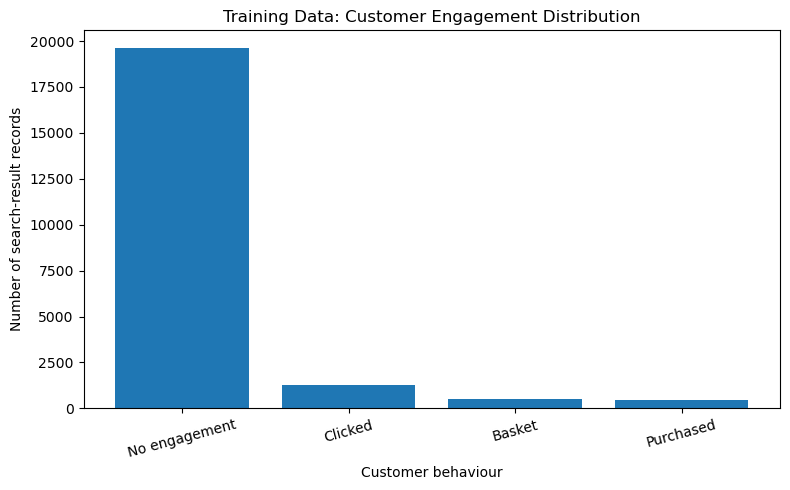

In [9]:

import matplotlib.pyplot as plt

train_data = searches_clean[
    searches_clean["search_id"].isin(train_ids)
]

counts = train_data["relevance_class"].value_counts().sort_index()

labels = ["No engagement", "Clicked", "Basket", "Purchased"]

plt.figure(figsize=(8, 5))
plt.bar(labels, [counts.get(i, 0) for i in range(4)])
plt.title("Training Data: Customer Engagement Distribution")
plt.xlabel("Customer behaviour")
plt.ylabel("Number of search-result records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


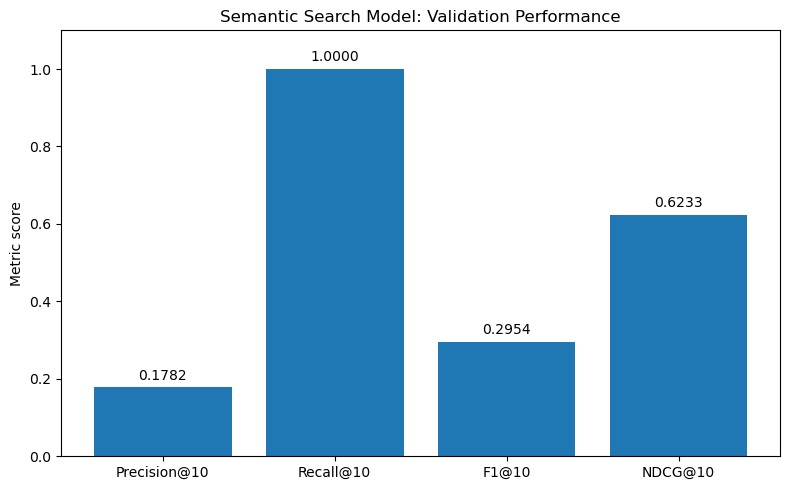

In [10]:
import matplotlib.pyplot as plt

metrics = ["Precision@10", "Recall@10", "F1@10", "NDCG@10"]
scores = [0.1782, 1.0000, 0.2954, 0.6233]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores)

plt.title("Semantic Search Model: Validation Performance")
plt.ylabel("Metric score")
plt.ylim(0, 1.1)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        score + 0.02,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

The visulaisations show that the most search-result records had no customer engagement and as stated before this creates an imbalance in the dataset hence the evlauation metrics and the limited pairs avalible in the fine tuning proccess. The second graph summarises the model raking metrics on unseen data